# Synthetic planner baseline model testing

This notebook tests four baseline classifiers on the leakage-aware synthetic feature tables produced by the processing contract. The task is enrollment-level risk screening: `risk_label = 1` for failed or withdrawn simulated outcomes and `0` for passed outcomes.

The experiment is a software and methodology check, not evidence of model effectiveness with real students. The simulator intentionally creates correlated variables and controlled scenario coverage. Results must therefore be reported as synthetic benchmark results.

## Why these four baselines?

- **Logistic regression** provides a transparent linear reference and probability output.
- **Random forest** captures nonlinear interactions and is robust to mixed planner features.
- **Extra trees** provides a randomized tree ensemble with a useful variance/bias comparison.
- **Histogram gradient boosting** tests a strong nonlinear boosting baseline.

No model is declared best from accuracy alone. The comparison reports accuracy, precision, recall, F1, balanced accuracy, ROC-AUC, PR-AUC, Brier score, and confusion matrices. The selection rule is validation PR-AUC first, validation ROC-AUC second, validation balanced accuracy third, and validation F1 fourth because a support-screening system must rank rare risk and account for both classes.

{30: (12000, 66), 60: (12000, 66), 90: (12000, 66)}


,cutoff_days,risk_count,non_risk_count,risk_pct
0,30,152,11848,1.27
1,60,152,11848,1.27
2,90,152,11848,1.27


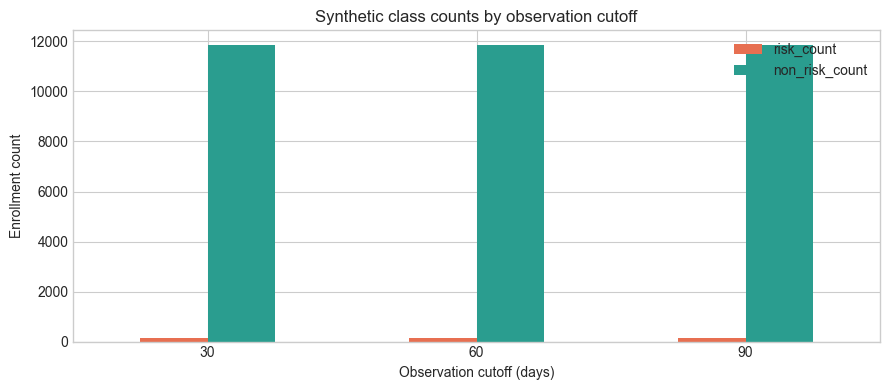

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.features.synthetic_features import build_cutoff_features
from src.models.synthetic_baseline import run_synthetic_baselines

DATA_DIR = ROOT / 'data' / 'raw' / 'synthetic'
CUTOFFS = (30, 60, 90)
RANDOM_STATE = 42
feature_sets = build_cutoff_features(DATA_DIR, CUTOFFS)
plt.style.use('seaborn-v0_8-whitegrid')
print({cutoff: frame.shape for cutoff, frame in feature_sets.items()})

class_balance = pd.DataFrame([
    {
        'cutoff_days': cutoff,
        'risk_count': int(frame['risk_label'].sum()),
        'non_risk_count': int((frame['risk_label'] == 0).sum()),
        'risk_pct': frame['risk_label'].mean() * 100,
    }
    for cutoff, frame in feature_sets.items()
])
display(class_balance.round(2))
class_balance.set_index('cutoff_days')[['risk_count', 'non_risk_count']].plot(
    kind='bar', figsize=(9, 4), color=['#e76f51', '#2a9d8f'],
    title='Synthetic class counts by observation cutoff'
)
plt.xlabel('Observation cutoff (days)')
plt.ylabel('Enrollment count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 1. Student-disjoint splitting

A student can have several enrollments. Splitting rows randomly could place one student's behaviour in both training and testing and inflate performance. This notebook first splits unique students, stratifying by whether the student has at least one risky enrollment, and then assigns all of that student's enrollments to one partition. This is a conservative test of generalization to unseen students.

In [2]:
IDENTIFIER_COLUMNS = {'enrollment_id', 'student_id', 'offering_id', 'course_id', 'faculty_id', 'department_id', 'program_id'}
TARGET_COLUMNS = {'risk_label', 'passed', 'withdrawn', 'requires_retake'}
DROP_COLUMNS = IDENTIFIER_COLUMNS | TARGET_COLUMNS | {'observation_cutoff_days'}

def student_split(frame):
    student_target = frame.groupby('student_id')['risk_label'].max().rename('student_risk')
    train_students, test_students = train_test_split(student_target.index, test_size=0.25, random_state=RANDOM_STATE, stratify=student_target.values)
    train = frame[frame['student_id'].isin(train_students)].copy()
    test = frame[frame['student_id'].isin(test_students)].copy()
    return train, test

def make_pipeline(X):
    numeric = X.select_dtypes(include='number').columns.tolist()
    categorical = X.select_dtypes(exclude='number').columns.tolist()
    numeric_steps = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    categorical_steps = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('numeric', numeric_steps, numeric), ('categorical', categorical_steps, categorical)], remainder='drop')

def model_candidates():
    return {
        'logistic_regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        'random_forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        'extra_trees': ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        'hist_gradient_boosting': HistGradientBoostingClassifier(max_iter=150, random_state=RANDOM_STATE),
    }

def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    return {
        'accuracy': accuracy_score(y_test, predictions),
        'precision': precision_score(y_test, predictions, zero_division=0),
        'recall': recall_score(y_test, predictions, zero_division=0),
        'f1': f1_score(y_test, predictions, zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(y_test, predictions),
        'roc_auc': roc_auc_score(y_test, probabilities),
        'confusion_matrix': confusion_matrix(y_test, predictions),
        'model': model,
    }

## 2. Train and compare models

Imputation and encoding are fitted inside each pipeline using training students only. The model matrix contains the non-identifier, non-label, non-cutoff fields returned by the processing contract; identifiers are excluded because they identify records rather than generalizable learning signals. Numeric fields receive median imputation and scaling, while categorical fields receive most-frequent imputation and one-hot encoding. The model comparison is repeated independently for 30, 60, and 90 days. A later cutoff can use more information, but the comparison must still respect the stated observation date.

In [3]:
metrics, fitted_models = run_synthetic_baselines(DATA_DIR, CUTOFFS, random_state=RANDOM_STATE)
results = []
for cutoff_text, evaluation_group in metrics['evaluations'].items():
    cutoff = int(cutoff_text)
    for name, evaluation in evaluation_group['models'].items():
        results.append({'cutoff_days': cutoff, 'model': name, **{key: value for key, value in evaluation.items() if not isinstance(value, (dict, list))}})

results_df = pd.DataFrame(results)
display(results_df.sort_values(['cutoff_days', 'validation_pr_auc'], ascending=[True, False]).round(4))

D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\AI PROJECTS\C++\Smart-Study-Planner\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,cutoff_days,model,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,pr_auc,brier_score,validation_pr_auc,validation_roc_auc,validation_balanced_accuracy,validation_f1,validation_selected_threshold,n_validation,selection_split,n_samples,n_train,n_test
2,30,extra_trees,0.9870,0.0,0.0,0.0,0.5000,0.9001,0.0777,0.0124,0.1091,0.9046,0.5000,0.0000,0.10,2400,student_disjoint_validation,12000,9000,3000
0,30,logistic_regression,0.9870,0.0,0.0,0.0,0.5000,0.9062,0.1037,0.0122,0.0951,0.9004,0.5000,0.0000,0.05,2400,student_disjoint_validation,12000,9000,3000
1,30,random_forest,0.9870,0.0,0.0,0.0,0.5000,0.8929,0.0823,0.0123,0.0836,0.9009,0.5000,0.0000,0.10,2400,student_disjoint_validation,12000,9000,3000
3,30,hist_gradient_boosting,0.9870,0.0,0.0,0.0,0.5000,0.8869,0.0951,0.0129,0.0785,0.9049,0.4998,0.0000,0.01,2400,student_disjoint_validation,12000,9000,3000
4,60,logistic_regression,0.9870,0.0,0.0,0.0,0.5000,0.9186,0.1152,0.0123,0.1212,0.9123,0.4998,0.0000,0.30,2400,student_disjoint_validation,12000,9000,3000
6,60,extra_trees,0.9870,0.0,0.0,0.0,0.5000,0.9049,0.0751,0.0126,0.1200,0.9202,0.5000,0.0000,0.10,2400,student_disjoint_validation,12000,9000,3000
5,60,random_forest,0.9870,0.0,0.0,0.0,0.5000,0.8968,0.0821,0.0125,0.1160,0.8949,0.5000,0.0000,0.10,2400,student_disjoint_validation,12000,9000,3000
7,60,hist_gradient_boosting,0.9867,0.0,0.0,0.0,0.4998,0.9107,0.0995,0.0130,0.0929,0.9162,0.4994,0.0000,0.02,2400,student_disjoint_validation,12000,9000,3000
10,90,extra_trees,0.9870,0.0,0.0,0.0,0.5000,0.9078,0.0701,0.0126,0.1497,0.9280,0.5000,0.0000,0.10,2400,student_disjoint_validation,12000,9000,3000
8,90,logistic_regression,0.9870,0.0,0.0,0.0,0.5000,0.9357,0.1117,0.0123,0.1455,0.9307,0.4994,0.0000,0.10,2400,student_disjoint_validation,12000,9000,3000


## 3. Baseline comparison visualization

ROC-AUC is plotted as the primary ranking metric, while balanced accuracy shows whether both classes are handled reasonably. These metrics are not interchangeable: a model can rank risk well while using a default threshold that produces a different confusion matrix.

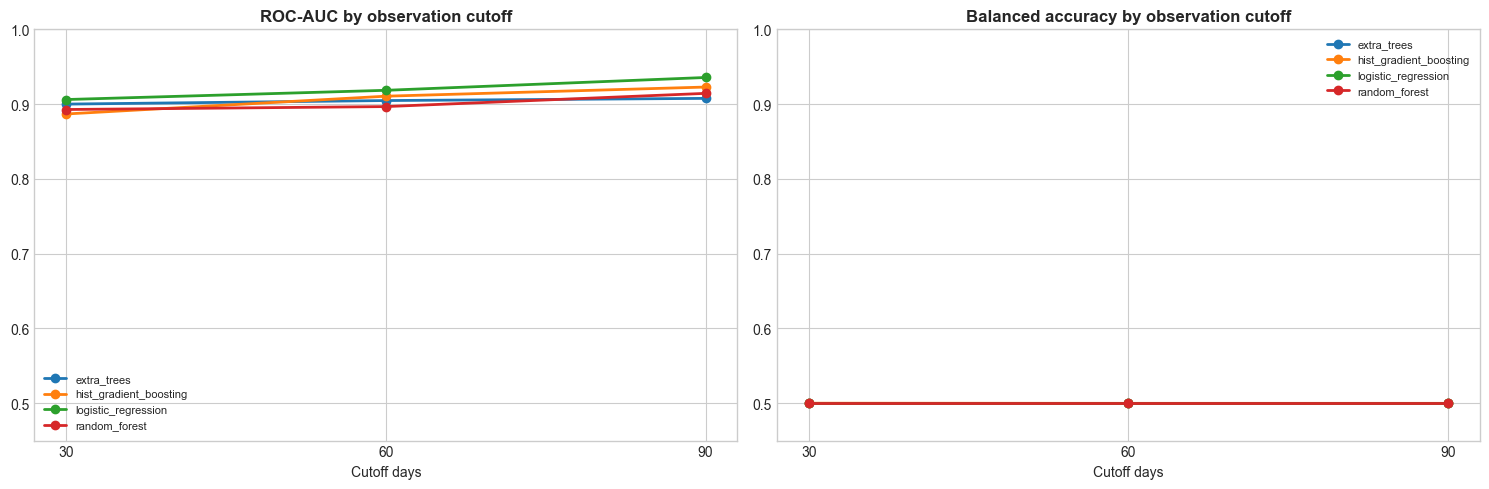

,cutoff_days,model,pr_auc,roc_auc,validation_pr_auc,validation_roc_auc,f1,recall,precision
0,30,extra_trees,0.0777,0.9001,0.1091,0.9046,0.0,0.0,0.0
1,60,logistic_regression,0.1152,0.9186,0.1212,0.9123,0.0,0.0,0.0
2,90,extra_trees,0.0701,0.9078,0.1497,0.9280,0.0,0.0,0.0


,cutoff_days,rank,model,roc_auc,balanced_accuracy,f1,recall,precision,accuracy
2,30,1,extra_trees,0.9001,0.5000,0.0,0.0,0.0,0.9870
0,30,2,logistic_regression,0.9062,0.5000,0.0,0.0,0.0,0.9870
1,30,3,random_forest,0.8929,0.5000,0.0,0.0,0.0,0.9870
3,30,4,hist_gradient_boosting,0.8869,0.5000,0.0,0.0,0.0,0.9870
4,60,1,logistic_regression,0.9186,0.5000,0.0,0.0,0.0,0.9870
6,60,2,extra_trees,0.9049,0.5000,0.0,0.0,0.0,0.9870
5,60,3,random_forest,0.8968,0.5000,0.0,0.0,0.0,0.9870
7,60,4,hist_gradient_boosting,0.9107,0.4998,0.0,0.0,0.0,0.9867
10,90,1,extra_trees,0.9078,0.5000,0.0,0.0,0.0,0.9870
8,90,2,logistic_regression,0.9357,0.5000,0.0,0.0,0.0,0.9870


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, group in results_df.groupby('model'):
    axes[0].plot(group['cutoff_days'], group['roc_auc'], marker='o', linewidth=2, label=name)
    axes[1].plot(group['cutoff_days'], group['balanced_accuracy'], marker='o', linewidth=2, label=name)
axes[0].set_title('ROC-AUC by observation cutoff', weight='bold')
axes[1].set_title('Balanced accuracy by observation cutoff', weight='bold')
for ax in axes:
    ax.set_xlabel('Cutoff days')
    ax.set_xticks(CUTOFFS)
    ax.set_ylim(0.45, 1.0)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

selected = (results_df.sort_values(['cutoff_days', 'validation_pr_auc', 'validation_roc_auc', 'validation_balanced_accuracy', 'validation_f1'], ascending=[True, False, False, False, False]).groupby('cutoff_days', as_index=False).first())
display(selected[['cutoff_days', 'model', 'pr_auc', 'roc_auc', 'validation_pr_auc', 'validation_roc_auc', 'f1', 'recall', 'precision']].round(4))

# This audit table makes the declared tie-breaking rule visible for every cutoff.
ranking = results_df.sort_values(
    ['cutoff_days', 'validation_pr_auc', 'validation_roc_auc', 'validation_balanced_accuracy', 'validation_f1'],
    ascending=[True, False, False, False, False]
).copy()
ranking['rank'] = ranking.groupby('cutoff_days').cumcount() + 1
display(ranking[['cutoff_days', 'rank', 'model', 'roc_auc', 'balanced_accuracy', 'f1', 'recall', 'precision', 'accuracy']].round(4))

## 4. Confusion matrices for the selected baseline

Each matrix uses actual class on the vertical axis and predicted class on the horizontal axis. The displayed matrices use the threshold selected on the validation partition, not an arbitrary default of 0.50. This preserves the locked-test evaluation contract and avoids presenting an all-negative default-threshold result as the operating policy. False negatives are risky in a support-screening setting because a learner who needs attention is missed. False positives consume support capacity. The matrices are therefore necessary even when a scalar metric appears strong. The next audit reports both counts and rates so that the colour intensity of a plot is not mistaken for a normalized error rate.

C:\Users\RAFISO~1\AppData\Local\Temp\ipykernel_23544\1287003582.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


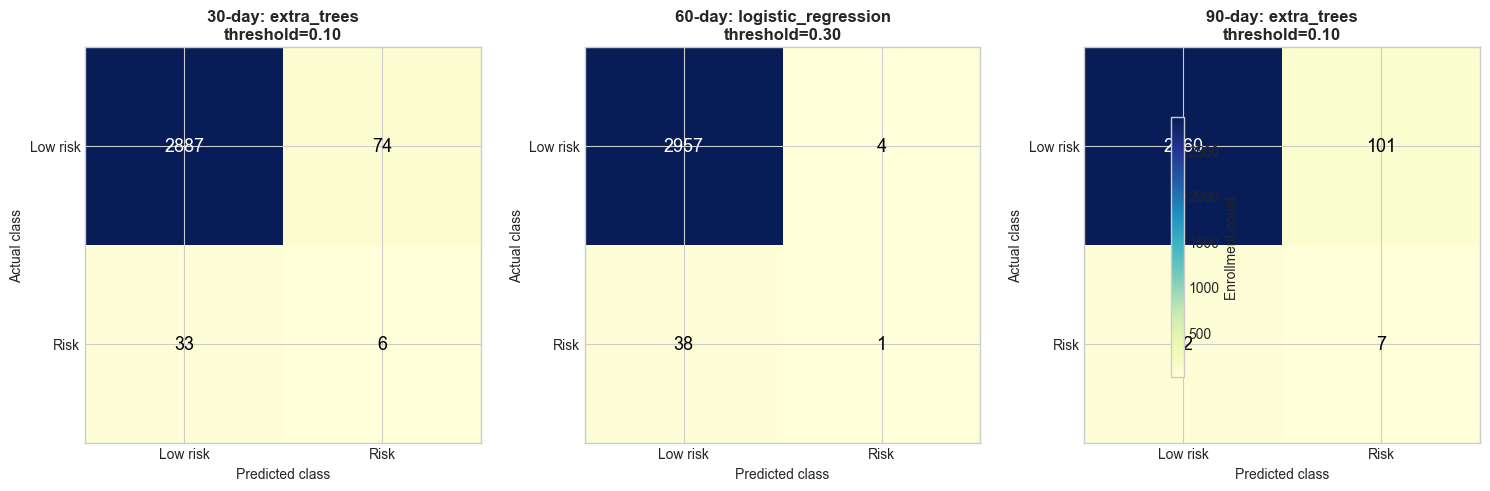

,cutoff_days,model,threshold,TN,FP,FN,TP,sensitivity_recall,specificity,false_positive_rate,false_negative_rate
0,30,extra_trees,0.1,2887,74,33,6,0.1538,0.9750,0.0250,0.8462
1,60,logistic_regression,0.3,2957,4,38,1,0.0256,0.9986,0.0014,0.9744
2,90,extra_trees,0.1,2860,101,32,7,0.1795,0.9659,0.0341,0.8205


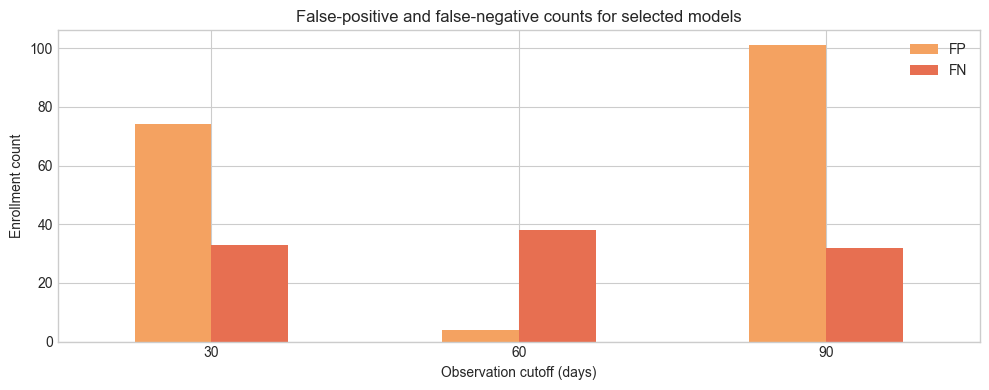

In [5]:
fig, axes = plt.subplots(1, len(CUTOFFS), figsize=(15, 4.5))
for ax, cutoff in zip(axes, CUTOFFS):
    evaluation = metrics['evaluations'][str(cutoff)]
    best_name = evaluation['best_model']
    model_metrics = evaluation['models'][best_name]
    threshold = model_metrics['validation_selected_threshold']
    matrix = np.array(model_metrics['test_at_validation_threshold']['confusion_matrix'])
    image = ax.imshow(matrix, cmap='YlGnBu')
    ax.set_title(f'{cutoff}-day: {best_name}\nthreshold={threshold:.2f}', weight='bold')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Actual class')
    ax.set_xticks([0, 1], ['Low risk', 'Risk'])
    ax.set_yticks([0, 1], ['Low risk', 'Risk'])
    for row in range(2):
        for col in range(2):
            ax.text(col, row, int(matrix[row, col]), ha='center', va='center', color='white' if matrix[row, col] > matrix.max() * .55 else 'black', fontsize=13)
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=.75, label='Enrollment count')
plt.tight_layout()
plt.show()

confusion_audit = []
for cutoff in CUTOFFS:
    evaluation = metrics['evaluations'][str(cutoff)]
    best_name = evaluation['best_model']
    model_metrics = evaluation['models'][best_name]
    threshold = model_metrics['validation_selected_threshold']
    tn, fp, fn, tp = np.array(model_metrics['test_at_validation_threshold']['confusion_matrix']).ravel()
    confusion_audit.append({
        'cutoff_days': cutoff,
        'model': best_name,
        'threshold': float(threshold),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'sensitivity_recall': tp / (tp + fn) if tp + fn else np.nan,
        'specificity': tn / (tn + fp) if tn + fp else np.nan,
        'false_positive_rate': fp / (fp + tn) if fp + tn else np.nan,
        'false_negative_rate': fn / (fn + tp) if fn + tp else np.nan,
    })
confusion_audit_df = pd.DataFrame(confusion_audit)
display(confusion_audit_df.round(4))

confusion_audit_df.set_index('cutoff_days')[['FP', 'FN']].plot(
    kind='bar', figsize=(10, 4), color=['#f4a261', '#e76f51'],
    title='False-positive and false-negative counts for selected models'
)
plt.xlabel('Observation cutoff (days)')
plt.ylabel('Enrollment count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Formal conclusion and limitations

The selected model is chosen separately at each cutoff using validation PR-AUC, validation ROC-AUC, validation balanced accuracy, and validation F1, not because one algorithm is universally superior. The locked-test metrics and confusion matrices are read only after this selection. These are development selections under the declared rule, not claims that the models are production-ready. The 30-day result may provide more intervention lead time; the 90-day result may have more evidence but leaves less time for support.

The current executed snapshot contains approximately 1.27% risky enrollments. At the default 0.5 classification threshold, the selected models therefore predict no positive test cases: recall and F1 are 0, and balanced accuracy is 0.5, despite ROC-AUC values above 0.90. This is a formal warning that ranking quality is not the same as an operationally useful alert policy. Threshold tuning, class-weight analysis, precision-recall analysis, calibration, and an intervention-cost decision rule are required before any support workflow could use these scores.

These metrics are synthetic benchmark outputs. They are affected by the simulator's controlled profile assignment and shared latent variables. They must not be compared directly with the OULAD results as if both datasets represented the same population or task. A production planner would require prospective, consented, de-identified institutional data, calibration, fairness analysis, intervention-cost analysis, and monitoring for drift.